# 発展：MPS・MPOと分子の量子回路を理解する

本編を終えた方への任意教材です。SVD・ボンド次元・回路生成の数学を扱います。
第一版の動作確認済み小規模デモを残し、末尾に今回の分子データとの対応を加えました。
本編の進行に、このノートの理解は必須ではありません。

**配列順の注意**：第一版の関数は回路図の上からの順へ変換します。
新版の分子配列はQiskitの標準順です。分子をMPSへ渡すときは下記で明示的に軸を反転します。
また、最終の第一版QPDE例は密なStatePreparation/UnitaryGateによる原理確認で、本編の実機回路ではありません。

In [1]:
# GitHub → Colab / ローカルの共通セットアップ
import sys, subprocess, importlib.util
from pathlib import Path
GITHUB_REPOSITORY = "https://github.com/QS-laboratory/IBM_handson.git"
GITHUB_REF = "main"  # 配布時には講師が検証済みタグまたはコミットへ固定します
try:
    IS_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IS_COLAB = False
if IS_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "qiskit==2.4.1", "qiskit-ibm-runtime==0.43.1", "pylatexenc==2.10"], check=True)
    checkout = Path("/content/IBM_handson")
    if not checkout.exists():
        subprocess.run(["git", "clone", GITHUB_REPOSITORY, str(checkout)], check=True)
    subprocess.run(["git", "-C", str(checkout), "fetch", "origin", GITHUB_REF, "--depth", "1"], check=True)
    subprocess.run(["git", "-C", str(checkout), "checkout", "--detach", "FETCH_HEAD"], check=True)
    WORKSHOP_ROOT = checkout / "hands_on"
else:
    candidates = [Path.cwd(), Path.cwd()/"hands_on", Path.cwd().parent]
    WORKSHOP_ROOT = next(p for p in candidates if (p/"src/workshop.py").exists())
sys.path.insert(0, str(WORKSHOP_ROOT / "src"))
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from workshop import *
import qiskit
print("Qiskit:", qiskit.__version__)
print("教材:", WORKSHOP_ROOT)
print("実機への送信は、明示的に有効化したセルだけが行います。")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

def show_circuit(qc):
    try:
        figure = qc.draw("mpl", fold=90)
        display(figure)
        plt.close(figure)
    except ImportError:
        print(qc.draw("text", fold=90))


Qiskit: 2.4.1
教材: /Users/sato/project/FTQC_HandsOn/hands_on
実機への送信は、明示的に有効化したセルだけが行います。


# MPS・MPOから量子回路へ：小さな系で理解するTQPDEの部品

**学生・企業人向け／目安60–90分＋発展20分**  
このノートでは、状態や演算子を「大きな配列」「小さなテンソルの鎖」「量子ゲート列」で表し、同じものかを数値で確かめます。

1. 3量子ビットの状態を準備し、MPSで表す
2. 特異値分解（SVD）で一般の状態をMPSにする
3. MPSで与えた目標状態に、浅い状態準備回路を合わせる
4. 2量子ビットの時間発展を、行列・MPO・回路で一致させる
5. 非可換な模型で、MPOの圧縮とユニタリ回路の最適化を区別する
6. 状態準備と時間発展を、位相差推定に組み合わせる

**動作範囲**：すべてローカルの理想計算。IBM実機・Fire Opal・認証情報は不要で、QPU時間を消費しません。論文のHubbard模型を再現するノートではなく、その仕組みを理解するための例です。

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from IPython.display import display
from tensor_demo import *
np.set_printoptions(precision=4, suppress=True)
verify()

def show_circuit(qc):
    # 数式と同じく、上からq0,q1,...をサイトの順とします。
    try:
        fig = qc.draw('mpl', fold=100)
        display(fig)
        plt.close(fig)
    except ImportError:
        print(qc.draw('text', fold=100))

Verified: MPS/MPO reconstruction, circuit ordering, ZZ implementation, QPDE likelihood.


## 1. 状態準備：回転してから、相関を広げる

目標を $|\psi(\theta)\rangle=\cos\theta|000\rangle+\sin\theta|111\rangle$ とします。
$\theta=\pi/4$ がGHZ状態、$\theta=0$ が積状態です。

最初のRYゲートで「0と1の振幅」を作り、2つのCNOTでその基底ラベルに相関を持たせます。
未知の量子状態を複製する操作ではありません。

**試すこと**：`theta`を0、0.2、π/4に変えて、確率とMPSの必要ボンド次元を比較してください。

state amplitudes: [0.7071+0.j 0.    +0.j 0.    +0.j 0.    +0.j 0.    +0.j 0.    +0.j
 0.    +0.j 0.7071+0.j]


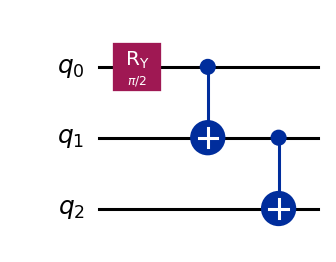

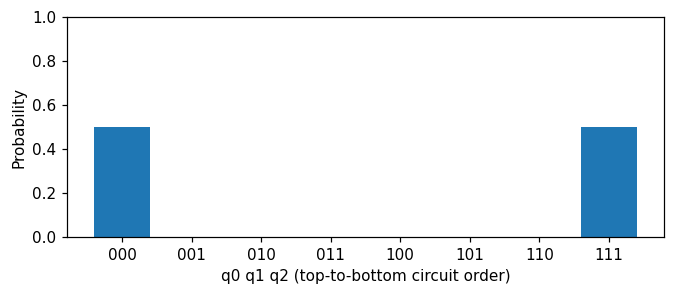

In [3]:
theta = np.pi / 4
prep_ghz = ghz_circuit(theta)
psi = circuit_state(prep_ghz)
show_circuit(prep_ghz)
print('state amplitudes:', psi)
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.bar([format(i, '03b') for i in range(8)], abs(psi)**2)
ax.set(xlabel='q0 q1 q2 (top-to-bottom circuit order)', ylabel='Probability', ylim=(0, 1))
plt.show()

### 同じ状態をMPSで表す

$\psi_{s_0s_1s_2}=\sum_{a,b} A^{s_0}_{0a}B^{s_1}_{ab}C^{s_2}_{b0}$。
$s_j$は実際の量子ビットの0/1、$a,b$はテンソル間をつなぐ**内部の添字（ボンド）**です。
ボンド次元2は、実機に量子ビットを2個追加するという意味ではありません。

この例ではボンドが「0の枝／1の枝」を受け渡します。
非ゼロ成分は $A^{0}_{0,0}=\cos\theta$, $A^{1}_{0,1}=\sin\theta$、
$B^{0}_{0,0}=B^{1}_{1,1}=C^{0}_{0,0}=C^{1}_{1,0}=1$。
ここでは配列と同じく、境界の添字は0、内部の添字は0/1と表記しています。

対応する回路を手で構成できる例なので、MPSの成分と各ゲートの働きを照合できます。
一般のMPSの各テンソルが、そのまま1つの量子ゲートになるわけではありません。

In [4]:
cores = ghz_mps(theta)
for site, core in enumerate(cores):
    print(f'site {site}: (left bond, physical, right bond) = {core.shape}')
    print(core)
psi_from_mps = mps_to_state(cores)
print('MPS vs circuit error:', np.linalg.norm(psi_from_mps - psi))
assert np.allclose(psi_from_mps, psi)

site 0: (left bond, physical, right bond) = (1, 2, 2)
[[[0.7071+0.j 0.    +0.j]
  [0.    +0.j 0.7071+0.j]]]
site 1: (left bond, physical, right bond) = (2, 2, 2)
[[[1.+0.j 0.+0.j]
  [0.+0.j 0.+0.j]]

 [[0.+0.j 0.+0.j]
  [0.+0.j 1.+0.j]]]
site 2: (left bond, physical, right bond) = (2, 2, 1)
[[[1.+0.j]
  [0.+0.j]]

 [[0.+0.j]
  [1.+0.j]]]
MPS vs circuit error: 0.0


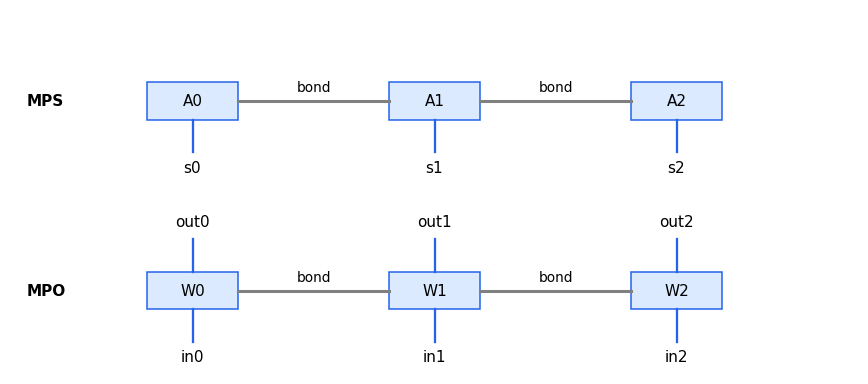

In [5]:
from matplotlib.patches import Rectangle
fig, axes = plt.subplots(2, 1, figsize=(8, 3.6))
for row, ax in enumerate(axes):
    ax.set(xlim=(-0.6, 5), ylim=(-1.0, 1.1))
    ax.axis('off')
    ax.text(-0.5, 0, 'MPS' if row == 0 else 'MPO', va='center', weight='bold')
    for site in range(3):
        x = 0.6 + 1.6*site
        if site < 2:
            ax.plot([x+0.3, x+1.3], [0, 0], color='gray', lw=2)
            ax.text(x+0.8, 0.12, 'bond', ha='center', fontsize=9)
        ax.add_patch(Rectangle((x-0.3, -0.23), 0.6, 0.46, facecolor='#dbeafe', edgecolor='#2563eb'))
        ax.text(x, 0, f'{"A" if row == 0 else "W"}{site}', ha='center', va='center')
        ax.plot([x, x], [-0.23, -0.62], color='#2563eb')
        ax.text(x, -0.86, f's{site}' if row == 0 else f'in{site}', ha='center')
        if row == 1:
            ax.plot([x, x], [0.23, 0.62], color='#2563eb')
            ax.text(x, 0.78, f'out{site}', ha='center')
plt.tight_layout()
plt.show()

## 2. 大きな配列からMPSを生成する：SVD

状態を「左のサイト｜残り」で行列に並べ直し、SVDで分けます。残りにも同じ処理を繰り返します。
全ての有意な特異値を残せば元の状態を再構成でき、小さな特異値を捨てれば近似になります。
特異値の数は、その切断面で必要なボンド次元を示します。

GHZ状態のボンド次元を1に制限すると相関を保てません。等しい特異値がある場合、どの近似状態が選ばれるかには自由度があります。

In [6]:
for chi in (1, 2):
    mps, spectra = state_to_mps(psi, 3, max_bond=chi)
    approx = mps_to_state(mps)
    norm = np.linalg.norm(approx)
    fidelity = abs(np.vdot(psi, approx / norm))**2
    print(f'chi <= {chi}: shapes={[a.shape for a in mps]}')
    print(f'  norm before renormalization={norm:.6f}, fidelity={fidelity:.6f}')
print('Singular values at first cut:', spectra[0])

chi <= 1: shapes=[(1, 2, 1), (1, 2, 1), (1, 2, 1)]
  norm before renormalization=0.707107, fidelity=0.500000
chi <= 2: shapes=[(1, 2, 2), (2, 2, 2), (2, 2, 1)]
  norm before renormalization=1.000000, fidelity=1.000000
Singular values at first cut: [0.7071 0.7071]


## 3. MPSを目標として、状態準備回路を生成する

今度は手で回路を答えられない例です。3サイトの横磁場Ising模型
$H=J(Z_0Z_1+Z_1Z_2)+h(X_0+X_1+X_2)$、$J=1,h=0.7$ の基底状態を使います。

小さな行列を厳密対角化 → MPSへ変換 → MPSを収縮して目標振幅を取り出す →
RY・CNOT回路の角度を古典最適化、という流れです。
実数の基底状態なのでRYだけで振幅を表せる回路を選びます。一般の複素状態には位相を変えるゲートも必要です。

**論文との対応**：古典計算で得た目標状態を浅いユニタリ回路で近似する考え方を体験します。
論文の大規模なMPSの作成・テンソル収縮・ゲートごとの最適化とは実装が異なります。
この例は配列を展開するので大規模系には拡張できません。

Ground-state energy: -2.7865868506743747
MPS shapes: [(1, 2, 2), (2, 2, 2), (2, 2, 1)]
Preparation fidelity: 1.0000000000000018
Prepared-state energy: -2.7865868506743743


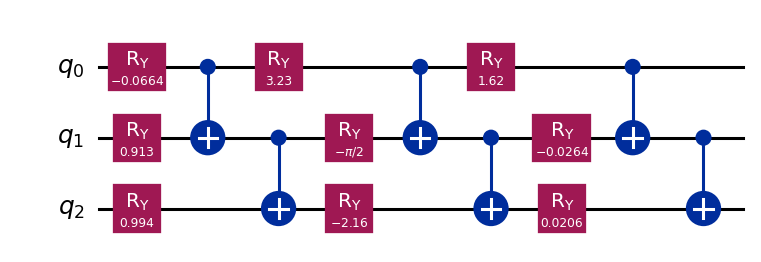

In [7]:
H = ising_hamiltonian()
energies, eigenstates = np.linalg.eigh(H)
ground, excited = eigenstates[:, 0], eigenstates[:, 1]
ground_mps, _ = state_to_mps(ground, 3)
target_state = mps_to_state(ground_mps)
print('Ground-state energy:', energies[0])
print('MPS shapes:', [a.shape for a in ground_mps])
prep_fit = fit_preparation(target_state, layers=3)
prepared = circuit_state(prep_fit)
print('Preparation fidelity:', abs(np.vdot(target_state, prepared))**2)
print('Prepared-state energy:', np.vdot(prepared, H @ prepared).real)
show_circuit(prep_fit)

## 4. 時間発展：2量子ビットならMPOと回路を手で書ける

$\hbar=1$ とし、$H=JZ_0Z_1$、$\alpha=Jt$ とします。
$(Z\otimes Z)^2=I$ なので、
$$U(t)=e^{-i\alpha Z\otimes Z}=\cos\alpha\,I\otimes I-i\sin\alpha\,Z\otimes Z.$$

この**演算子の2項の和**を、内部の添字$a=0,1$で表せばボンド次元2のMPOです。
各サイトには出力と入力の添字があるので、MPOテンソルの形は `(left, out, in, right)`。
MPSは状態、MPOは状態に作用する演算子を表します。

回路では `CNOT → RZ(2α) → CNOT` で同じ時間発展を厳密に実装できます。
RZの定義に1/2が入るので角度は2αです。

MPO shapes: [(1, 2, 2, 2), (2, 2, 2, 1)]
Matrix vs MPO: 0.0
Matrix vs circuit: 0.0
Diagonal phases: [0.9553-0.2955j 0.9553+0.2955j 0.9553+0.2955j 0.9553-0.2955j]


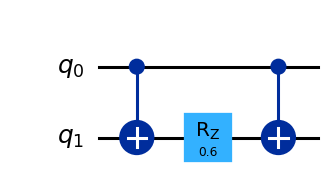

In [8]:
alpha = 0.3
U_zz = expm(-1j * alpha * kron(Z, Z))
mpo_zz = zz_mpo(alpha)
circuit_zz = zz_circuit(alpha)
show_circuit(circuit_zz)
print('MPO shapes:', [w.shape for w in mpo_zz])
print('Matrix vs MPO:', relative_error(mpo_to_operator(mpo_zz), U_zz))
print('Matrix vs circuit:', relative_error(circuit_matrix(circuit_zz), U_zz))
print('Diagonal phases:', np.diag(U_zz))
assert np.allclose(U_zz, mpo_to_operator(mpo_zz))
assert np.allclose(U_zz, circuit_matrix(circuit_zz))

### MPOをMPSに作用させる

入力の添字をつないで和を取ると、$|\psi'\rangle=U|\psi\rangle$ が計算できます。
各サイトで $B_{(l,a),o,(r,b)}=\sum_i W_{l,o,i,r}A_{a,i,b}$。
作用直後のボンド次元は、MPOとMPSのボンド次元の積になります。

ここでは $|++\rangle$ を時間発展させます。ZZの時間発展は振幅の絶対値を変えず位相を変えるため、
計算基底の確率だけでは変化が見えません。状態ベクトルの一致を確かめます。

Input MPS shapes: [(1, 2, 1), (1, 2, 1)]
Output MPS shapes: [(1, 2, 2), (2, 2, 1)]
Output amplitudes: [0.4777-0.1478j 0.4777+0.1478j 0.4777+0.1478j 0.4777-0.1478j]


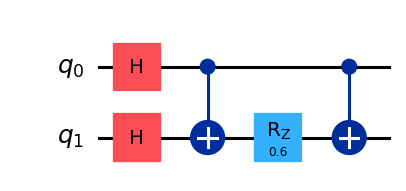

In [9]:
plus = np.array([1, 1], dtype=complex) / np.sqrt(2)
input_mps = [plus.reshape(1, 2, 1), plus.reshape(1, 2, 1)]
output_mps = apply_mpo_to_mps(mpo_zz, input_mps)
evolved_mps = mps_to_state(output_mps)
evolution_qc = QuantumCircuit(2)
evolution_qc.h([0, 1])
evolution_qc.compose(circuit_zz, inplace=True)
print('Input MPS shapes:', [a.shape for a in input_mps])
print('Output MPS shapes:', [a.shape for a in output_mps])
print('Output amplitudes:', evolved_mps)
assert np.allclose(evolved_mps, U_zz @ kron(plus, plus))
assert np.allclose(evolved_mps, circuit_state(evolution_qc))
show_circuit(evolution_qc)

## 5. 非可換な時間発展：MPO圧縮と回路圧縮

先ほどの3サイト模型では、ZZ項とX項が可換でないため、単にそれぞれの時間発展を掛けるだけでは厳密になりません。
まず参照 $U_{\rm ref}=e^{-iH\Delta t}$ を作り、行列の出力・入力の添字をサイトごとに組み替えてSVDし、MPOにします。

**重要な実験**：MPOのボンド次元を切り詰めた演算子は、一般にユニタリ性を失います。
MPOが小さいことと、そのまま量子ゲートとして実行できることは別です。
ここでの誤差は $\|U_{\rm approx}-U_{\rm ref}\|_F/\|U_{\rm ref}\|_F$、
ユニタリ性の誤差は $\|U^\dagger U-I\|_F/\sqrt{2^N}$ とします。

chi=1: shapes=[(1, 2, 2, 1), (1, 2, 2, 1), (1, 2, 2, 1)]
  relative error=0.516416, unitarity error=0.266685
chi=2: shapes=[(1, 2, 2, 2), (2, 2, 2, 2), (2, 2, 2, 1)]
  relative error=0.0152253, unitarity error=0.000231809
chi=4: shapes=[(1, 2, 2, 4), (4, 2, 2, 4), (4, 2, 2, 1)]
  relative error=7.72906e-16, unitarity error=1.00026e-15


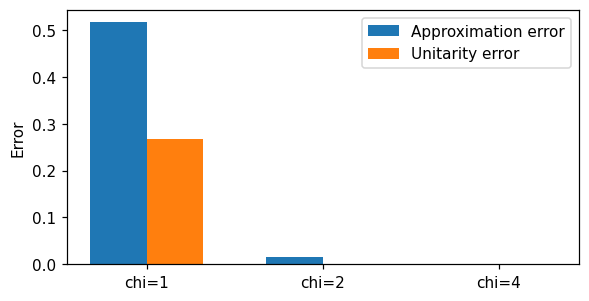

In [10]:
dt = 0.4
U_ref = expm(-1j * H * dt)
mpo_rows = []
for chi in (1, 2, 4):
    mpo, _ = operator_to_mpo(U_ref, 3, max_bond=chi)
    U_mpo = mpo_to_operator(mpo)
    row = (chi, relative_error(U_mpo, U_ref), unitarity_error(U_mpo))
    mpo_rows.append(row)
    print(f'chi={chi}: shapes={[w.shape for w in mpo]}')
    print(f'  relative error={row[1]:.6g}, unitarity error={row[2]:.6g}')
fig, ax = plt.subplots(figsize=(6, 3))
x = np.arange(len(mpo_rows))
ax.bar(x-0.16, [r[1] for r in mpo_rows], 0.32, label='Approximation error')
ax.bar(x+0.16, [r[2] for r in mpo_rows], 0.32, label='Unitarity error')
ax.set(xticks=x, xticklabels=['chi=1', 'chi=2', 'chi=4'], ylabel='Error')
ax.legend()
plt.show()

### ユニタリ性を保つ回路を生成する

RXと隣接RZZの角度を変数にして、MPOから再構成した参照演算子へ回路を合わせます。
どの角度でも回路はユニタリなので、近似誤差はあっても物理的に実行できます。
同じ層数のTrotter回路を初期値とし、角度の最適化前後で比較します。

**試すこと**：`dt`や層数を変え、ゲート数と誤差の関係を説明してください。
少ないゲートで同じ精度を出せるかが圧縮の評価です。改善は模型・時間幅・回路の形に依存します。
この小さな例で論文のゲート削減率や量子優位性を実証するものではありません。

layers=1, RZZ gates=2
  Trotter error=0.207048, optimized error=0.194345
  unitarity error=1.62e-16
layers=2, RZZ gates=4
  Trotter error=0.100487, optimized error=0.006110
  unitarity error=2.90e-16
layers=3, RZZ gates=6
  Trotter error=0.066635, optimized error=0.000000
  unitarity error=1.88e-16


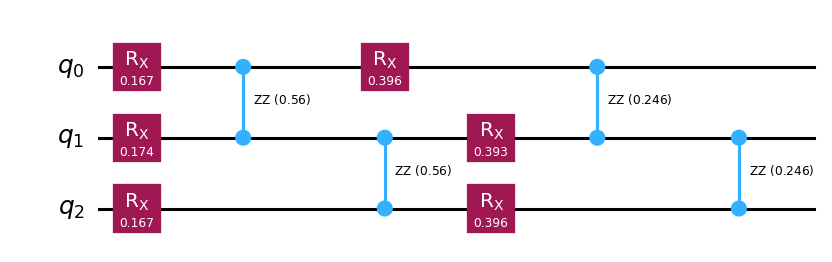

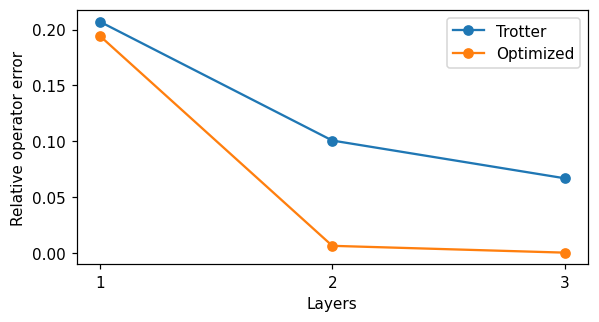

In [11]:
reference_mpo, _ = operator_to_mpo(U_ref, 3)
reference_from_mpo = mpo_to_operator(reference_mpo)
comparison = []
optimized_by_layers = {}
for layers in (1, 2, 3):
    baseline = evolution_ansatz(trotter_parameters(dt, layers), layers=layers)
    optimized = fit_evolution(reference_from_mpo, dt, layers)
    optimized_by_layers[layers] = optimized
    before = relative_error(circuit_matrix(baseline), U_ref)
    after = relative_error(circuit_matrix(optimized), U_ref)
    comparison.append((layers, before, after))
    print(f'layers={layers}, RZZ gates={optimized.count_ops().get("rzz", 0)}')
    print(f'  Trotter error={before:.6f}, optimized error={after:.6f}')
    print(f'  unitarity error={unitarity_error(circuit_matrix(optimized)):.2e}')
    assert after <= before + 1e-10
U_step_circuit = optimized_by_layers[2]  # 近似誤差が見える2層を次の実験に使用
show_circuit(U_step_circuit)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot([r[0] for r in comparison], [r[1] for r in comparison], 'o-', label='Trotter')
ax.plot([r[0] for r in comparison], [r[2] for r in comparison], 'o-', label='Optimized')
ax.set(xlabel='Layers', ylabel='Relative operator error', xticks=[1, 2, 3])
ax.legend()
plt.show()

### 短い時間の回路を繰り返すとどうなるか

$U_{\rm step}$ を繰り返すと長時間の計算になります。各ステップの小さな誤差も蓄積します。
両方がユニタリなら、三角不等式より
$\|U_{\rm step}^{m}-U_{\rm ref}^{m}\|_F \le m\|U_{\rm step}-U_{\rm ref}\|_F$。
実機では、これにゲート実行のノイズが加わります。

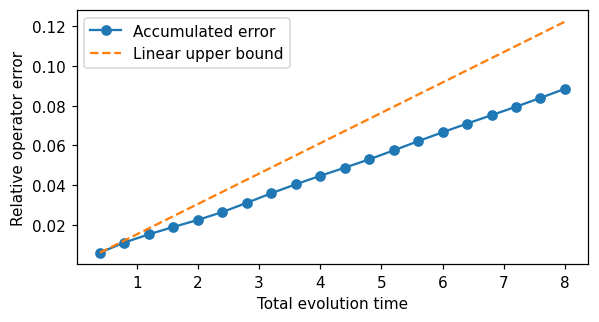

In [12]:
U_step = circuit_matrix(U_step_circuit)
steps = np.arange(1, 21)
errors = [relative_error(np.linalg.matrix_power(U_step, int(m)), expm(-1j*H*dt*m)) for m in steps]
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(steps*dt, errors, 'o-', label='Accumulated error')
ax.plot(steps*dt, steps*relative_error(U_step, U_ref), '--', label='Linear upper bound')
ax.set(xlabel='Total evolution time', ylabel='Relative operator error')
ax.legend()
plt.show()

## 6. 発展：部品を位相差推定につなぐ

補助量子ビットを加え、
$U_{\rm prep}|0\cdots0\rangle=(|0\rangle|g\rangle+|1\rangle|e\rangle)/\sqrt2$
を準備します。系だけに時間発展をかけ、補助量子ビットに位相 $\varepsilon t$ を与え、
最後に $U_{\rm prep}^\dagger$ で戻します。

全量子ビットが0になる確率は、固有状態を厳密に準備し、厳密な時間発展を使うと
$$p(0\cdots0)=\frac{1+\cos[(E_e-E_g-\varepsilon)t]}{2}.$$
ここでは補助1＋系3の計4量子ビット。ピーク付近からエネルギー差を読み取ります。
コサインは周期的なので、探索範囲を広げると別のピークが出ます。

**教材上の省略**：この最終例の準備には、小規模系用の`StatePreparation`を使います。
前節の基底状態準備だけでは基底・励起状態の重ね合わせ準備には足りません。
論文ではこの重ね合わせもMPSとして用意し、浅い回路に近似します。
ここでの密な状態準備や`UnitaryGate`による厳密演算子の埋め込みは大規模化に適しません。

Exact gap: 0.43027945341132323


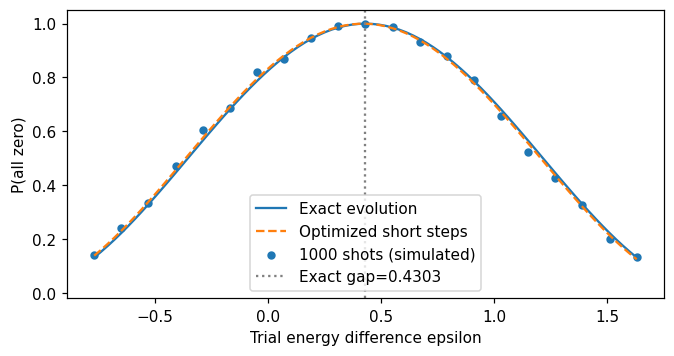

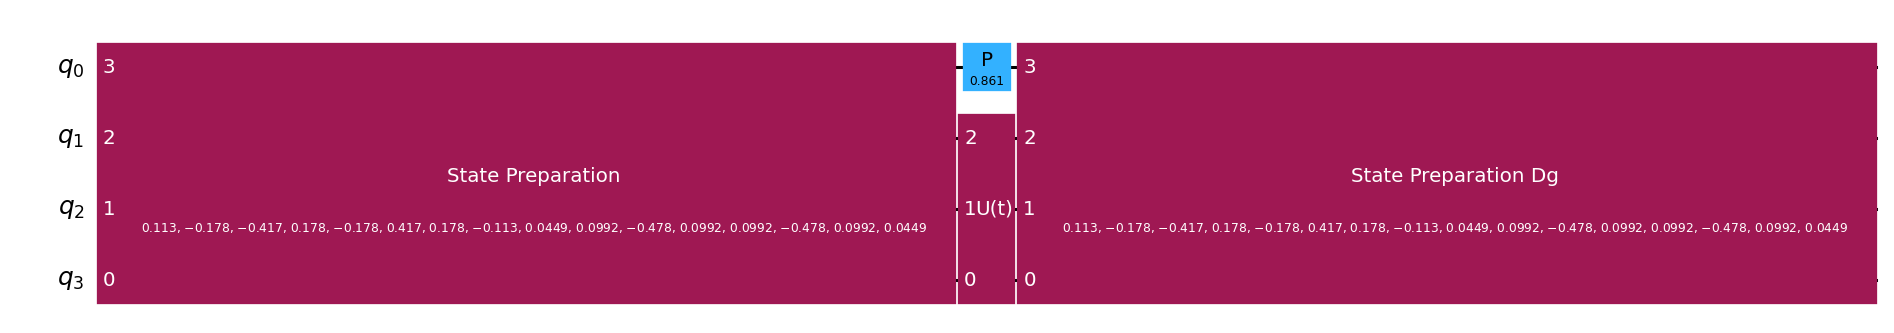

In [13]:
gap = energies[1] - energies[0]
t = 2.0
U_exact_t = expm(-1j*H*t)
m = int(round(t/dt))
U_approx_t = np.linalg.matrix_power(U_step, m)
epsilon_values = np.linspace(gap-1.2, gap+1.2, 81)
exact_probs, approx_probs = [], []
for epsilon in epsilon_values:
    exact_qc = qpde_circuit(ground, excited, U_exact_t, t, epsilon)
    approx_qc = qpde_circuit(ground, excited, U_approx_t, t, epsilon)
    exact_probs.append(abs(circuit_state(exact_qc)[0])**2)
    approx_probs.append(abs(circuit_state(approx_qc)[0])**2)
expected = (1+np.cos((gap-epsilon_values)*t))/2
assert np.allclose(exact_probs, expected, atol=1e-10)
# 有限ショットによるばらつきだけを追加。実機ノイズは含まない。
shots = 1000
rng = np.random.default_rng(42)
sampled = rng.binomial(shots, np.clip(approx_probs, 0, 1)) / shots
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(epsilon_values, exact_probs, label='Exact evolution')
ax.plot(epsilon_values, approx_probs, '--', label='Optimized short steps')
ax.scatter(epsilon_values[::4], sampled[::4], s=20, label=f'{shots} shots (simulated)')
ax.axvline(gap, color='gray', linestyle=':', label=f'Exact gap={gap:.4f}')
ax.set(xlabel='Trial energy difference epsilon', ylabel='P(all zero)', ylim=(-0.02, 1.05))
ax.legend()
plt.show()
print('Exact gap:', gap)
show_circuit(qpde_circuit(ground, excited, U_exact_t, t, gap))

### 最終回路の中身を見る

`StatePreparation`や`U(t)`は大きな箱に見えますが、実行するには基本ゲートへ分解します。
以下は理想的な全結合を仮定した分解です。IBM実機の接続制約・ネイティブゲートへの変換やノイズは含みません。
前節の浅い回路と比べ、一般の密な行列を機械的に分解するコストを確認できます。

In [14]:
from qiskit import transpile
qpde = qpde_circuit(ground, excited, U_exact_t, t, gap)
qpde_basic = transpile(qpde, basis_gates=['rz', 'sx', 'x', 'cx'], optimization_level=2, seed_transpiler=7)
print('Dense exact QPDE circuit: depth=', qpde_basic.depth(), ', gates=', dict(qpde_basic.count_ops()))
# 全回路を表示する場合は次行のコメントを外してください。
# show_circuit(qpde_basic)

Dense exact QPDE circuit: depth= 132 , gates= {'rz': 84, 'sx': 59, 'cx': 39, 'x': 2}


## 振り返りと講師用メモ

- **状態準備**：目標状態を作る。MPSはその状態の表現で、回路は準備の手順。
- **時間発展**：任意の入力状態に作用する演算子を作る。MPOは演算子の表現。
- **ボンド次元**：切断面で必要な相関の大きさ。回路のゲート数・深さとは別の指標。
- **圧縮**：SVDでテンソルのランクを落とす方法と、ユニタリゲートの角度を最適化する方法を区別する。
- **論文への接続**：基底・励起状態の重ね合わせ準備と、短時間発展を浅い回路で近似し、回路を繰り返して干渉を読む。

**参加者への問い**
1. theta=0でMPSの必要ボンド次元が小さくなるのはなぜか。
2. 状態準備の忠実度が高くても、時間発展演算子全体が正しいとは限らないのはなぜか。
3. ユニタリ性の誤差がゼロなら、時間発展の近似誤差もゼロと言えるか。
4. ショット数を増やせば、回路近似に由来する偏りも消えるか。

**講師向け回答の要点**：1. 積状態なので各切断のランクは1。2. 1つの入力での一致は全入力での一致を保証しない。
3. 誤ったユニタリも存在する。4. 消えるのは統計変動で、系統的な近似誤差は残る。

**スケールに関する注意**：このノートの厳密対角化・密な行列指数・配列への復元は指数的なメモリを使います。
SVD関数も教育用に配列全体を読み込みます。論文のテンソルネットワークを用いた効率的な大規模前処理や量子優位性を、このノートで再現しているわけではありません。

**出典**
- S. Kanno et al., *Tensor-based quantum phase difference estimation for large-scale demonstration*, PNAS 122, e2425026122 (2025). https://doi.org/10.1073/pnas.2425026122
- 同論文の補足資料 S1（位相差推定）・S2（ユニタリ圧縮）。親フォルダ内のPDFを参照。
- 著者公開コード：https://github.com/sk888ks/TQPDE_open （本ノートは説明用の独立実装）。
- Qiskit Quantum Information API：https://quantum.cloud.ibm.com/docs/en/api/qiskit/quantum_info

**表記**：NumPyのテンソルは回路図の上からq0,q1,q2の順。Qiskit標準の配列順は逆なので、補助関数内でビット順を変換しています。

## 今回の分子とMPS/MPOを対応させる

本編の対象分子について、厳密な分子状態からMPSを作り、打ち切りの影響を確認します。
これは密な配列を使う教育用の処理で、大規模化できる実装ではありません。

本編の配布回路はRY/CXとPauli積の最適化で作ったもので、このMPS/MPOを使うテンソル最適化で生成したものではありません。
論文ではテンソルネットワークを使い、軌道局在化・並べ替えも工夫しています。

In [15]:
import workshop as molecular_workshop
molecular_meta, molecular_arrays=molecular_workshop.load_model("ethylene")
n=molecular_meta["system_qubits"]
# Qiskit配列(q[n-1]...q0)を、MPSで扱うq0,q1,...の軸順に変換。
state_topdown=molecular_arrays["singlet"].reshape((2,)*n).transpose(tuple(reversed(range(n)))).reshape(-1)
for chi in [1,2,4]:
    mps,_=state_to_mps(state_topdown,n,max_bond=chi)
    reconstruction=mps_to_state(mps)
    reconstruction/=np.linalg.norm(reconstruction)
    print("chi",chi,"fidelity",abs(np.vdot(state_topdown,reconstruction))**2,"shapes",[a.shape for a in mps])
# 分子の小さな厳密時間発展もMPOへ分解できる。
U_native=expm(-1j*molecular_arrays["hamiltonian"]*.5)
axes=list(reversed(range(n)))+list(reversed(range(n,2*n)))
U_topdown=U_native.reshape((2,)*(2*n)).transpose(axes).reshape(2**n,2**n)
for chi in [1,2,4,16]:
    mpo,_=operator_to_mpo(U_topdown,n,max_bond=chi)
    reconstructed=mpo_to_operator(mpo)
    print("MPO chi",chi,"relative error",relative_error(reconstructed,U_topdown),"unitarity error",unitarity_error(reconstructed))

chi 1 fidelity 0.9371262706377101 shapes [(1, 2, 1), (1, 2, 1), (1, 2, 1), (1, 2, 1)]
chi 2 fidelity 1.0 shapes [(1, 2, 2), (2, 2, 2), (2, 2, 2), (2, 2, 1)]
chi 4 fidelity 1.0 shapes [(1, 2, 2), (2, 2, 2), (2, 2, 2), (2, 2, 1)]
MPO chi 1 relative error 0.1466572437415003 unitarity error 0.02150834785901643
MPO chi 2 relative error 0.04385534336993535 unitarity error 0.01655968752477535
MPO chi 4 relative error 0.0008227511415911642 unitarity error 1.7457518779476384e-05
MPO chi 16 relative error 5.738573730639806e-16 unitarity error 1.1265301481335006e-15
